# Round 1 diagnostic (Lender 3)

What happened in Stage 1, using the instructor's file `Round1_Diagnostic_33.csv`, and what it means for Round 2.

### Key takeaways
1. **We made 30.9 M€ (5th of 12)** with the largest market share (49%). The leader made 73.3 M€ with 37.5%: we won many loans on **thin margins**.
2. **Winner's curse is real and measured**: on the loans we won, our model predicted 11.05% default; the realized rate was 12.25% (+1.2 points).
3. **Adverse selection in every risk bucket**: the loans we *won* defaulted more than the loans we *lost*. Rivals use their private signal to take the safer borrowers and leave us the rest. It is strongest when we have no private signal (`signal3 = 0`).
4. **We were too cheap**: rivals charged a median ~4% above break-even on safe borrowers and much more on risky ones; when we won, we were often far below the next offer.
5. **Risky borrowers were our most profitable segment**, so refusing them would be a mistake. About 9% of applicants received **no rival offer** at all.
6. **Borrowers who prefer us** (2% loyalty) are our best clients: lower default, highest profit.

**Caveat on "rivals".** For each loan the instructor drew one of the four Lender 1 teams and one of the four Lender 2 teams at random (one of each is an LLM). `competing1` / `competing2` are therefore a **mix of teams**: the rows "Lender 1 teams" and "Lender 2 teams" below are *not* comparable to any single team in the league table.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

LOAN = 10_000
BONUS = 0.02
LENDERS = ["Us (L3)", "Lender 1 teams", "Lender 2 teams"]
N_BUCKETS = 10
pd.set_option("display.width", 200)

## 0. Load and rebuild the market

We add our predicted default probability (`pd`, the Stage 1 signal3 model) and rebuild, for every loan, **which lender won it**: the borrower takes the lowest rate after a 2% discount on their preferred lender (`borrowertype`: 1 = Lender 1, 2 = Lender 2, 3 = us). The rebuild must reproduce the instructor's numbers exactly.

In [2]:
diag = pd.read_csv(RAW_DIR / "Round1_Diagnostic_33.csv")
pds = pd.read_csv(PROCESSED_DIR / "signal3_new_applications_predictions_catboost.csv")[["id", "pd"]]
apps = pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round1.csv")[["id", "signal3", "employment", "income"]]
df = diag.merge(pds, on="id", how="left", validate="one_to_one").merge(apps, on="id", how="left", validate="one_to_one")
assert len(df) == 100_000 and df["pd"].notna().all()

rates = df[["own", "competing1", "competing2"]].to_numpy()          # columns: us, L1, L2
offered = ~np.isnan(rates)
effective = np.where(offered, rates, np.inf)
preferred_col = df["borrowertype"].map({3: 0, 1: 1, 2: 2}).to_numpy()
effective[np.arange(len(df)), preferred_col] -= BONUS

has_offer = offered.any(axis=1)
df["winner"] = np.where(has_offer, np.array(LENDERS)[effective.argmin(axis=1)], "No loan")
df["rate_won"] = np.where(has_offer, rates[np.arange(len(df)), effective.argmin(axis=1)], np.nan)
df["profit_winner"] = np.where(has_offer, np.where(df["default"] == 1, -LOAN, LOAN * df["rate_won"]), 0.0)
df["break_even"] = df["pd"] / (1 - df["pd"])
df["bucket"] = pd.qcut(df["pd"], N_BUCKETS, labels=False) + 1
won_mask = df["winner"] == "Us (L3)"

# best rival offer as seen by the borrower (after the 2% preference); inf = no rival offer
df["rival_best"] = np.minimum(df["competing1"].fillna(np.inf) - BONUS * (df["borrowertype"] == 1),
                              df["competing2"].fillna(np.inf) - BONUS * (df["borrowertype"] == 2))
df["no_rival_offer"] = np.isinf(df["rival_best"])

assert (won_mask == (df["accepted"] == 1)).all(), "winner rebuild does not match 'accepted'"
assert np.isclose(df.loc[won_mask, "profit_winner"].sum(), df["profit"].sum())
print(f"Rebuild OK: {len(df):,} loans, our profit {df['profit'].sum():,.0f} €")

Rebuild OK: 100,000 loans, our profit 30,908,296 €


## 1. Overall picture

### 1a. Who won what (on our 100,000 applicants)

In [3]:
rows = {}
for lender, col in zip(LENDERS, ["own", "competing1", "competing2"]):
    won = df[df["winner"] == lender]
    rows[lender] = {
        "offer rate": df[col].notna().mean(),
        "loans won": len(won),
        "market share": len(won) / len(df),
        "default rate on won": won["default"].mean(),
        "avg rate on won": won["rate_won"].mean(),
        "profit (M€)": won["profit_winner"].sum() / 1e6,
        "profit per loan won (€)": won["profit_winner"].mean(),
    }
print(f"Applicants: {len(df):,} | default rate {df['default'].mean():.2%} | our mean predicted PD {df['pd'].mean():.2%} | "
      f"nobody made an offer: {(df['winner'] == 'No loan').sum()}")
pd.DataFrame(rows).T.style.format({"offer rate": "{:.1%}", "loans won": "{:,.0f}", "market share": "{:.1%}",
                                   "default rate on won": "{:.2%}", "avg rate on won": "{:.1%}",
                                   "profit (M€)": "{:.2f}", "profit per loan won (€)": "{:,.0f}"})

Applicants: 100,000 | default rate 9.95% | our mean predicted PD 9.93% | nobody made an offer: 33


,offer rate,loans won,market share,default rate on won,avg rate on won,profit (M€),profit per loan won (€)
Us (L3),99.9%,"49,159",49.2%,12.25%,22.7%,30.91,629
Lender 1 teams,65.6%,"25,797",25.8%,7.06%,11.4%,7.77,301
Lender 2 teams,74.8%,"25,011",25.0%,8.37%,13.1%,7.49,300


### 1b. Winner's curse on our loans

If our PD were right on the loans we won, realized defaults would equal predicted defaults. The gap is the extra risk that comes with being chosen. It is smaller for borrowers who **prefer us**: we keep them even when a rival is slightly cheaper, so they are less "picked over".

In [4]:
ours = df[won_mask]
print(f"Loans we won: {len(ours):,} | predicted default {ours['pd'].mean():.2%} | realized {ours['default'].mean():.2%} | "
      f"gap {(ours['default'].mean() - ours['pd'].mean()) * 100:+.2f} points")
print(f"Defaults cost {ours['default'].sum() * LOAN / 1e6:.1f} M€; interest on repaid loans earned "
      f"{ours.loc[ours['default'] == 0, 'profit'].sum() / 1e6:.1f} M€\n")

(df.assign(won=won_mask)
   .groupby(df["borrowertype"].map({1: "prefers Lender 1", 2: "prefers Lender 2", 3: "prefers us"}))
   .apply(lambda g: pd.Series({"our win rate": g["won"].mean(),
                               "predicted default (won)": g.loc[g["won"], "pd"].mean(),
                               "realized default (won)": g.loc[g["won"], "default"].mean(),
                               "our profit (M€)": g["profit"].sum() / 1e6}), include_groups=False)
   .rename_axis("borrower preference")
   .style.format({"our win rate": "{:.1%}", "predicted default (won)": "{:.1%}", "realized default (won)": "{:.1%}",
                  "our profit (M€)": "{:.2f}"}))

Loans we won: 49,159 | predicted default 11.05% | realized 12.25% | gap +1.20 points
Defaults cost 60.2 M€; interest on repaid loans earned 91.1 M€



,our win rate,predicted default (won),realized default (won),our profit (M€)
borrower preference,,,,
prefers Lender 1,40.4%,12.5%,13.9%,9.14
prefers Lender 2,39.9%,12.9%,14.2%,9.51
prefers us,67.1%,9.1%,10.1%,12.25


### 1c. How the rivals priced

Each lender's rate is compared with the **break-even rate of our PD**, `pd/(1−pd)` (rivals price on their own PD, which we do not see; ours is the common yardstick).

               offer rate median rate median markup over break-even
Us (L3)             99.9%       17.0%                          7.5%
Lender 1 teams      65.6%       12.8%                          3.8%
Lender 2 teams      74.8%       14.4%                          4.5%


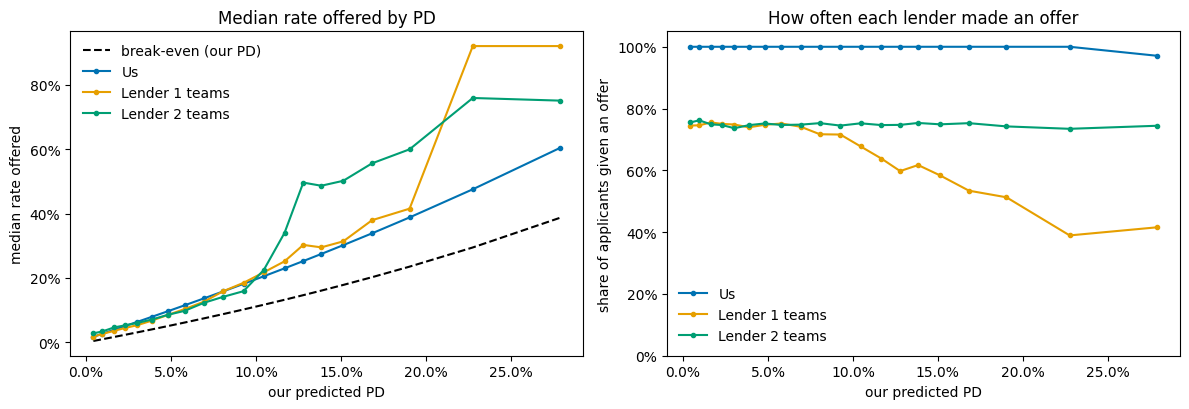

In [5]:
print(pd.DataFrame({
    lender: {"offer rate": f"{df[col].notna().mean():.1%}",
             "median rate": f"{df[col].median():.1%}",
             "median markup over break-even": f"{(df[col] - df['break_even']).median():.1%}"}
    for lender, col in zip(LENDERS, ["own", "competing1", "competing2"])}).T)

df["pd_bin"] = pd.qcut(df["pd"], 20)
curve = df.groupby("pd_bin", observed=True).agg(
    pd_mid=("pd", "median"), own=("own", "median"), competing1=("competing1", "median"),
    competing2=("competing2", "median"), break_even=("break_even", "median"),
    us_offer=("own", lambda s: s.notna().mean()), l1_offer=("competing1", lambda s: s.notna().mean()),
    l2_offer=("competing2", lambda s: s.notna().mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(curve["pd_mid"], curve["break_even"], "k--", lw=1.5, label="break-even (our PD)")
for color, (col, name) in zip(COLORS, [("own", "Us"), ("competing1", "Lender 1 teams"), ("competing2", "Lender 2 teams")]):
    axes[0].plot(curve["pd_mid"], curve[col], "o-", ms=3, color=color, label=name)
axes[0].set(xlabel="our predicted PD", ylabel="median rate offered", title="Median rate offered by PD")
for color, (col, name) in zip(COLORS, [("us_offer", "Us"), ("l1_offer", "Lender 1 teams"), ("l2_offer", "Lender 2 teams")]):
    axes[1].plot(curve["pd_mid"], curve[col], "o-", ms=3, color=color, label=name)
axes[1].set(xlabel="our predicted PD", ylabel="share of applicants given an offer", title="How often each lender made an offer",
            ylim=(0, 1.05))
for a in axes:
    a.legend(frameon=False)
    a.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## 2. By risk bucket: where we made money and where it went wrong

10 equal-size buckets by **our** PD (1 = safest).

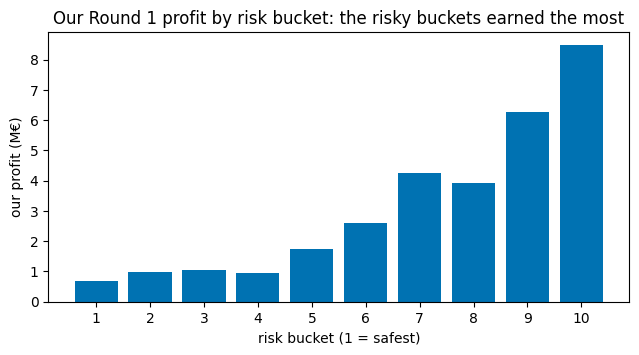

,our_PD,win_rate,profit_M,default_won,avg_rate_won,profit_per_loan_won
bucket,,,,,,
1,0.7%,48%,0.67,0.8%,2.2%,138
2,2.0%,46%,0.97,2.3%,4.5%,210
3,3.4%,39%,1.04,4.1%,7.1%,270
4,5.3%,36%,0.96,7.2%,10.6%,266
5,7.5%,39%,1.76,9.0%,14.8%,452
6,9.9%,44%,2.59,11.4%,19.4%,584
7,12.2%,56%,4.25,13.4%,24.2%,754
8,14.5%,56%,3.93,17.0%,29.0%,701
9,17.9%,62%,6.26,19.2%,36.4%,"1,011"


In [6]:
x = np.arange(1, N_BUCKETS + 1)
base = df.groupby("bucket").agg(our_PD=("pd", "mean"), win_rate=("accepted", "mean"),
                                profit_M=("profit", lambda s: s.sum() / 1e6))
base["default_won"] = df[won_mask].groupby("bucket")["default"].mean()
base["avg_rate_won"] = df[won_mask].groupby("bucket")["own"].mean()
base["profit_per_loan_won"] = df[won_mask].groupby("bucket")["profit"].mean()

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(x, base["profit_M"], color=COLORS[0])
ax.set(xlabel="risk bucket (1 = safest)", ylabel="our profit (M€)", xticks=x,
       title="Our Round 1 profit by risk bucket: the risky buckets earned the most")
plt.show()
base.style.format({"our_PD": "{:.1%}", "win_rate": "{:.0%}", "profit_M": "{:.2f}", "default_won": "{:.1%}",
                   "avg_rate_won": "{:.1%}", "profit_per_loan_won": "{:,.0f}"})

### 2a. Adverse selection: loans we **won** vs loans we **lost**

In the same bucket, borrowers we won and borrowers we lost would default equally if there were no adverse selection. Lost loans defaulting *less* means rivals took the good borrowers.

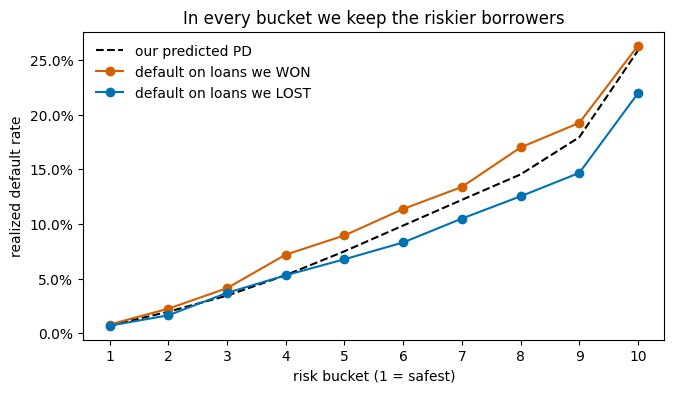

,our PD,default on WON,default on LOST,gap (pts)
bucket,,,,
1,0.7%,0.8%,0.7%,+0.1
2,2.0%,2.3%,1.7%,+0.6
3,3.4%,4.1%,3.7%,+0.4
4,5.3%,7.2%,5.3%,+1.9
5,7.5%,9.0%,6.8%,+2.2
6,9.9%,11.4%,8.3%,+3.1
7,12.2%,13.4%,10.5%,+2.9
8,14.5%,17.0%,12.5%,+4.5
9,17.9%,19.2%,14.7%,+4.6


In [7]:
lost_mask = (~won_mask) & df["own"].notna()
sel = pd.DataFrame({"our PD": base["our_PD"],
                    "default on WON": df[won_mask].groupby("bucket")["default"].mean(),
                    "default on LOST": df[lost_mask].groupby("bucket")["default"].mean()})
sel["gap (pts)"] = (sel["default on WON"] - sel["default on LOST"]) * 100

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(x, sel["our PD"], "k--", lw=1.5, label="our predicted PD")
ax.plot(x, sel["default on WON"], "o-", color=COLORS[5], label="default on loans we WON")
ax.plot(x, sel["default on LOST"], "o-", color=COLORS[0], label="default on loans we LOST")
ax.set(xlabel="risk bucket (1 = safest)", ylabel="realized default rate", xticks=x,
       title="In every bucket we keep the riskier borrowers")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
plt.show()
sel.style.format({"our PD": "{:.1%}", "default on WON": "{:.1%}", "default on LOST": "{:.1%}", "gap (pts)": "{:+.1f}"})

**Which borrowers?** Same comparison by segment. The selection is strongest where we know least (`signal3 = 0`) and for students.

In [8]:
segs = {
    "signal3 = 0 (no private info)": df["signal3"] == 0,
    "signal3 > 0": df["signal3"] > 0,
    "student": df["employment"] == "student",
    "employed": df["employment"] == "employed",
    "unemployed": df["employment"] == "unemployed",
    "retired": df["employment"] == "retired",
}
pd.DataFrame({name: {"applicants": m.sum(), "our win rate": won_mask[m].mean(),
                     "default on WON": df.loc[m & won_mask, "default"].mean(),
                     "default on LOST": df.loc[m & lost_mask, "default"].mean(),
                     "our profit (M€)": df.loc[m, "profit"].sum() / 1e6}
              for name, m in segs.items()}).T.style.format(
    {"applicants": "{:,.0f}", "our win rate": "{:.1%}", "default on WON": "{:.1%}", "default on LOST": "{:.1%}",
     "our profit (M€)": "{:.2f}"})

,applicants,our win rate,default on WON,default on LOST,our profit (M€)
signal3 = 0 (no private info),"20,935",42.1%,13.5%,6.6%,5.97
signal3 > 0,"79,065",51.0%,12.0%,8.0%,24.94
student,"16,050",54.4%,15.4%,10.3%,5.96
employed,"57,825",44.3%,9.4%,6.7%,12.68
unemployed,"14,537",66.1%,17.8%,10.3%,9.44
retired,"11,588",45.1%,10.6%,7.3%,2.82


### 2b. Were we too cheap?

- **When we lost** a loan to a rival: how far above the winning offer were we, and how often was the winner's rate **below our break-even** (a sign they knew the borrower was safer than we thought).
- **When we won** against a rival offer: how far below the next offer we were (the margin we could have added and still won).
- **Applicants with no rival offer**: they accept any rate up to 100%; we served them at our normal rate.

In [9]:
df["our_eff"] = df["own"] - BONUS * (df["borrowertype"] == 3)
lost_to_rival = lost_mask & ~df["no_rival_offer"]
won_contested = won_mask & ~df["no_rival_offer"]
cheap = pd.DataFrame({
    "lost: we were above the winner by (median, pts)": (df.loc[lost_to_rival, "our_eff"] - df.loc[lost_to_rival, "rival_best"])
        .groupby(df.loc[lost_to_rival, "bucket"]).median() * 100,
    "lost: winner priced below OUR break-even": (df.loc[lost_to_rival, "rival_best"] < df.loc[lost_to_rival, "break_even"])
        .groupby(df.loc[lost_to_rival, "bucket"]).mean(),
    "won: room below next offer (median, pts)": (df.loc[won_contested, "rival_best"] - df.loc[won_contested, "our_eff"])
        .groupby(df.loc[won_contested, "bucket"]).median() * 100,
    "no rival offer (share of applicants)": df.groupby("bucket")["no_rival_offer"].mean(),
    "default when no rival offer": df[df["no_rival_offer"]].groupby("bucket")["default"].mean(),
})
print(f"Applicants with no rival offer: {df['no_rival_offer'].mean():.1%} (default {df.loc[df['no_rival_offer'], 'default'].mean():.1%} "
      f"vs {df['default'].mean():.1%} overall); {df.loc[won_mask, 'no_rival_offer'].mean():.0%} of the loans we won")
cheap.style.format({c: ("{:.1f}" if "pts" in c else "{:.1%}") for c in cheap.columns})

Applicants with no rival offer: 8.8% (default 13.6% vs 9.9% overall); 18% of the loans we won


,"lost: we were above the winner by (median, pts)",lost: winner priced below OUR break-even,"won: room below next offer (median, pts)",no rival offer (share of applicants),default when no rival offer
bucket,,,,,
1,1.6,53.1%,1.8,6.2%,0.3%
2,1.9,31.6%,1.5,6.2%,2.4%
3,2.5,31.0%,1.5,6.6%,3.8%
4,3.4,31.1%,2.7,6.6%,6.8%
5,4.4,30.2%,6.4,7.0%,8.4%
6,5.9,33.0%,27.4,7.6%,10.5%
7,6.8,29.0%,31.3,9.4%,13.0%
8,9.9,41.2%,33.7,9.7%,17.1%
9,14.5,56.2%,46.9,12.4%,19.3%


## 3. What to change in Round 2

Generated from the tables above.

In [10]:
s3 = segs["signal3 = 0 (no private info)"]
print("1. Raise margins: we won contested loans with a median room of "
      f"{cheap['won: room below next offer (median, pts)'].iloc[4:].median():.0f} points below the next offer in buckets 5–10.")
print(f"2. Margins must grow with risk: adverse selection in {(sel['gap (pts)'] > 0).sum()} of 10 buckets, "
      f"largest gap {sel['gap (pts)'].max():+.1f} pts (bucket {sel['gap (pts)'].idxmax()}).")
print(f"3. Do NOT refuse risky borrowers: the riskiest bucket earned {base['profit_M'].iloc[-1]:.1f} M€, the most of any bucket.")
print(f"4. Where we know least (signal3 = 0), rivals take the good borrowers: default on lost "
      f"{df.loc[s3 & lost_mask, 'default'].mean():.1%} vs won {df.loc[s3 & won_mask, 'default'].mean():.1%}.")
print(f"5. {df['no_rival_offer'].mean():.1%} of applicants got no rival offer; we priced them like contested loans.")

1. Raise margins: we won contested loans with a median room of 33 points below the next offer in buckets 5–10.
2. Margins must grow with risk: adverse selection in 10 of 10 buckets, largest gap +4.6 pts (bucket 9).
3. Do NOT refuse risky borrowers: the riskiest bucket earned 8.5 M€, the most of any bucket.
4. Where we know least (signal3 = 0), rivals take the good borrowers: default on lost 6.6% vs won 13.5%.
5. 8.8% of applicants got no rival offer; we priced them like contested loans.
